# SECOM – Fault Detection in Semiconductor Manufacturing

Feasibility study: predicting production failures from sensor and process measurement data (SECOM dataset, UCI Machine Learning Repository). The pipeline covers data preparation, exploratory analysis, feature selection, model training and a systematic comparison of different strategies for dealing with the strongly imbalanced class distribution.

**Requirements:** `numpy`, `pandas`, `matplotlib`, `seaborn`, `missingno`, `scipy`, `scikit-learn` (1.8), `imbalanced-learn`, `ipywidgets`. The data files `secom.data`, `secom_labels.data` (and `secom.names`) from the [UCI repository](https://archive.ics.uci.edu/dataset/179/secom) are expected in a folder `secom/` next to this notebook.

In [1]:
# Imports

import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import missingno as msno
import ipywidgets as widgets

import sklearn
import imblearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, classification_report, matthews_corrcoef, f1_score, recall_score, precision_score, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

from imblearn.over_sampling import SMOTE

SEED = 33
np.random.seed(SEED)

print(f"Python: {platform.python_version()}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"imbalanced-learn: {imblearn.__version__}")

Python: 3.13.0
scikit-learn: 1.8.0
imbalanced-learn: 0.14.2


## Loading and merging the data

In [2]:
# Load sensor/process measurement data (590 features, no header row in the raw file)
df = pd.read_csv('secom/secom.data', 
                header=None, 
                sep=r'\s+'
                )

print((f'Dataset size (without label and timestamps): {df.shape[0]} rows, {df.shape[1]} columns'))

Dataset size (without label and timestamps): 1567 rows, 590 columns


In [3]:
# Load the corresponding labels (pass/failure) and the timestamp of each run
labels = pd.read_csv(
    'secom/secom_labels.data',
    header=None,
    sep=r'\s+',
    names=['label', 'timestamp'],
)
labels['timestamp'] = pd.to_datetime(labels['timestamp'], format='%d/%m/%Y %H:%M:%S')
labels.head()

,label,timestamp
0,-1,2008-07-19 11:55:00
1,-1,2008-07-19 12:32:00
2,1,2008-07-19 13:17:00
3,-1,2008-07-19 14:43:00
4,-1,2008-07-19 15:22:00


In [4]:
# Merge labels and sensor data row by row (same order and length)
df = pd.concat([labels, df], axis=1)

print(f"Period of the runs: {df['timestamp'].min()} to {df['timestamp'].max()}")

Period of the runs: 2008-07-19 11:55:00 to 2008-10-17 06:07:00


## Exploratory Data Analysis (EDA)

### Class distribution

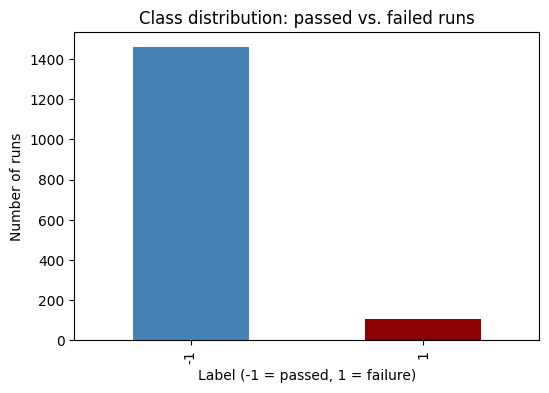

Failed runs in percent: 6.64%


In [5]:
# Show the basic class imbalance: passed vs. failed runs
plt.figure(figsize=(6, 4))
df['label'].value_counts().plot(kind='bar', color=['steelblue', 'darkred'])
plt.xlabel('Label (-1 = passed, 1 = failure)')
plt.ylabel('Number of runs')
plt.title('Class distribution: passed vs. failed runs')
plt.show()

print(f'Failed runs in percent: {df["label"].value_counts(normalize=True)[1] * 100:.2f}%')

### Missing values

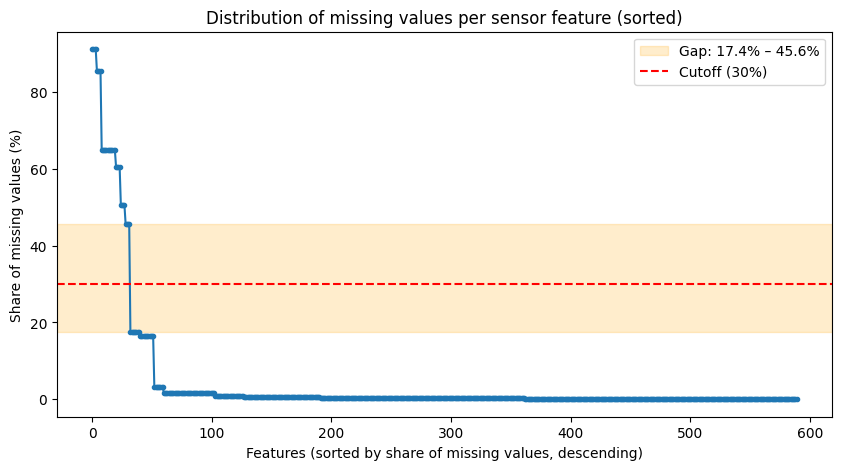

52 of 590 features have no missing values
Median: 0.38%, Max: 91.19%
Largest gap in the sorted distribution: 17.4% to 45.6%


In [6]:
# Compute and plot the share of missing values per sensor feature
# Only over the 590 sensor features, without label and timestamp (both have no
# missing values and would otherwise distort the number of complete features and
# the median).
missing_pct = df.drop(columns=['label', 'timestamp']).isnull().sum() / len(df) * 100

sorted_missing = missing_pct.sort_values(ascending=False).reset_index(drop=True)

# Find the largest gap in the sorted distribution to show it in the figure together
# with the 30% cutoff used later (see preprocessing pipeline).
gap_sizes = sorted_missing.diff().abs()
gap_idx = gap_sizes.idxmax()
gap_hi, gap_lo = sorted_missing[gap_idx - 1], sorted_missing[gap_idx]

plt.figure(figsize=(10, 5))
plt.plot(sorted_missing.index, sorted_missing.values, marker='.', linestyle='-')
plt.axhspan(gap_lo, gap_hi, color='orange', alpha=0.2,
            label=f'Gap: {gap_lo:.1f}% – {gap_hi:.1f}%')
plt.axhline(30, color='red', linestyle='--', label='Cutoff (30%)')
plt.xlabel('Features (sorted by share of missing values, descending)')
plt.ylabel('Share of missing values (%)')
plt.title('Distribution of missing values per sensor feature (sorted)')
plt.legend()
plt.show()

print(f"{(missing_pct == 0).sum()} of {len(missing_pct)} features have no missing values")
print(f"Median: {missing_pct.median():.2f}%, Max: {missing_pct.max():.2f}%")
print(f"Largest gap in the sorted distribution: {gap_lo:.1f}% to {gap_hi:.1f}%")

In [7]:
# Determine a cutoff for the share of missing values to remove features with too many missing values
gaps = sorted_missing.diff().abs()
gaps.nlargest(10)

32     28.206765
8      20.612636
52     13.337588
24      9.891512
4       5.615826
28      5.041481
20      4.403318
60      1.723038
40      0.829611
103     0.638162
dtype: float64

### Constant and redundant features

In [8]:
# Identify truly constant and quasi-constant (low coefficient of variation) sensor features
sensors = df.drop(columns=['label', 'timestamp'])

constant_cols = sensors.columns[sensors.nunique(dropna=True) <= 1]
print(f"Truly constant features: {len(constant_cols)}")

cv = sensors.std() / sensors.mean().abs()
near_constant_cols = cv[cv < 0.01].index.difference(constant_cols)
print(f"Additional low-variability features (CV < 1%): {len(near_constant_cols)}")

low_info_cols = constant_cols.union(near_constant_cols)
len(low_info_cols)

Truly constant features: 116
Additional low-variability features (CV < 1%): 15


131

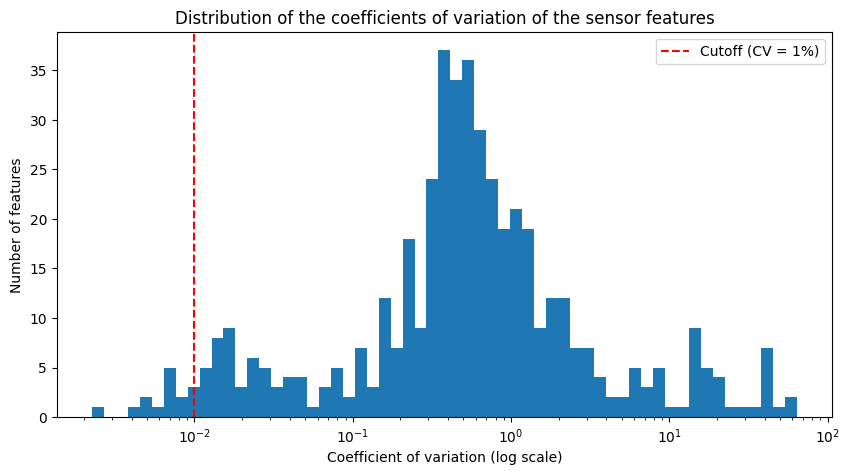

112 features without a defined CV (mean = 0)


In [9]:
# Distribution of the coefficients of variation (defined, positive values only) to place the cutoff
cv_finite = cv.replace([np.inf, -np.inf], np.nan).dropna()
cv_finite = cv_finite[cv_finite > 0]

plt.figure(figsize=(10, 5))
plt.hist(cv_finite, bins=np.logspace(np.log10(cv_finite.min()), np.log10(cv_finite.max()), 60))
plt.xscale('log')
plt.axvline(0.01, color='red', linestyle='--', label='Cutoff (CV = 1%)')
plt.xlabel('Coefficient of variation (log scale)')
plt.ylabel('Number of features')
plt.title('Distribution of the coefficients of variation of the sensor features')
plt.legend()
plt.show()

undefined_cv = len(cv) - len(cv.replace([np.inf, -np.inf], np.nan).dropna())
print(f"{undefined_cv} features without a defined CV (mean = 0)")

### Duplicates

In [10]:
# Identify duplicated sensor features
duplicate_cols = sensors.columns[sensors.T.duplicated()]
print(f"Number of duplicated sensor features: {len(duplicate_cols)}")
print(f"Of these, already removed by the low-variability filter: {len(set(duplicate_cols).intersection(low_info_cols))}")

# Duplicate check on the informative sensor features only (not the constant ones),
# to see whether there is redundancy beyond the constant columns
informative_sensors = sensors.drop(columns=low_info_cols)
duplicate_cols_informative = informative_sensors.columns[informative_sensors.T.duplicated()]
print(f"Number of duplicated informative sensor features: {len(duplicate_cols_informative)}")

# Identify duplicates on row level
duplicate_rows = df.duplicated(subset=sensors.columns, keep=False)
print(f"Number of duplicated rows (based on sensor features): {duplicate_rows.sum()}")    

Number of duplicated sensor features: 104
Of these, already removed by the low-variability filter: 104
Number of duplicated informative sensor features: 0
Number of duplicated rows (based on sensor features): 0


### Structure of the missingness

Top 20 features by share of missing values (for the missingness plots)


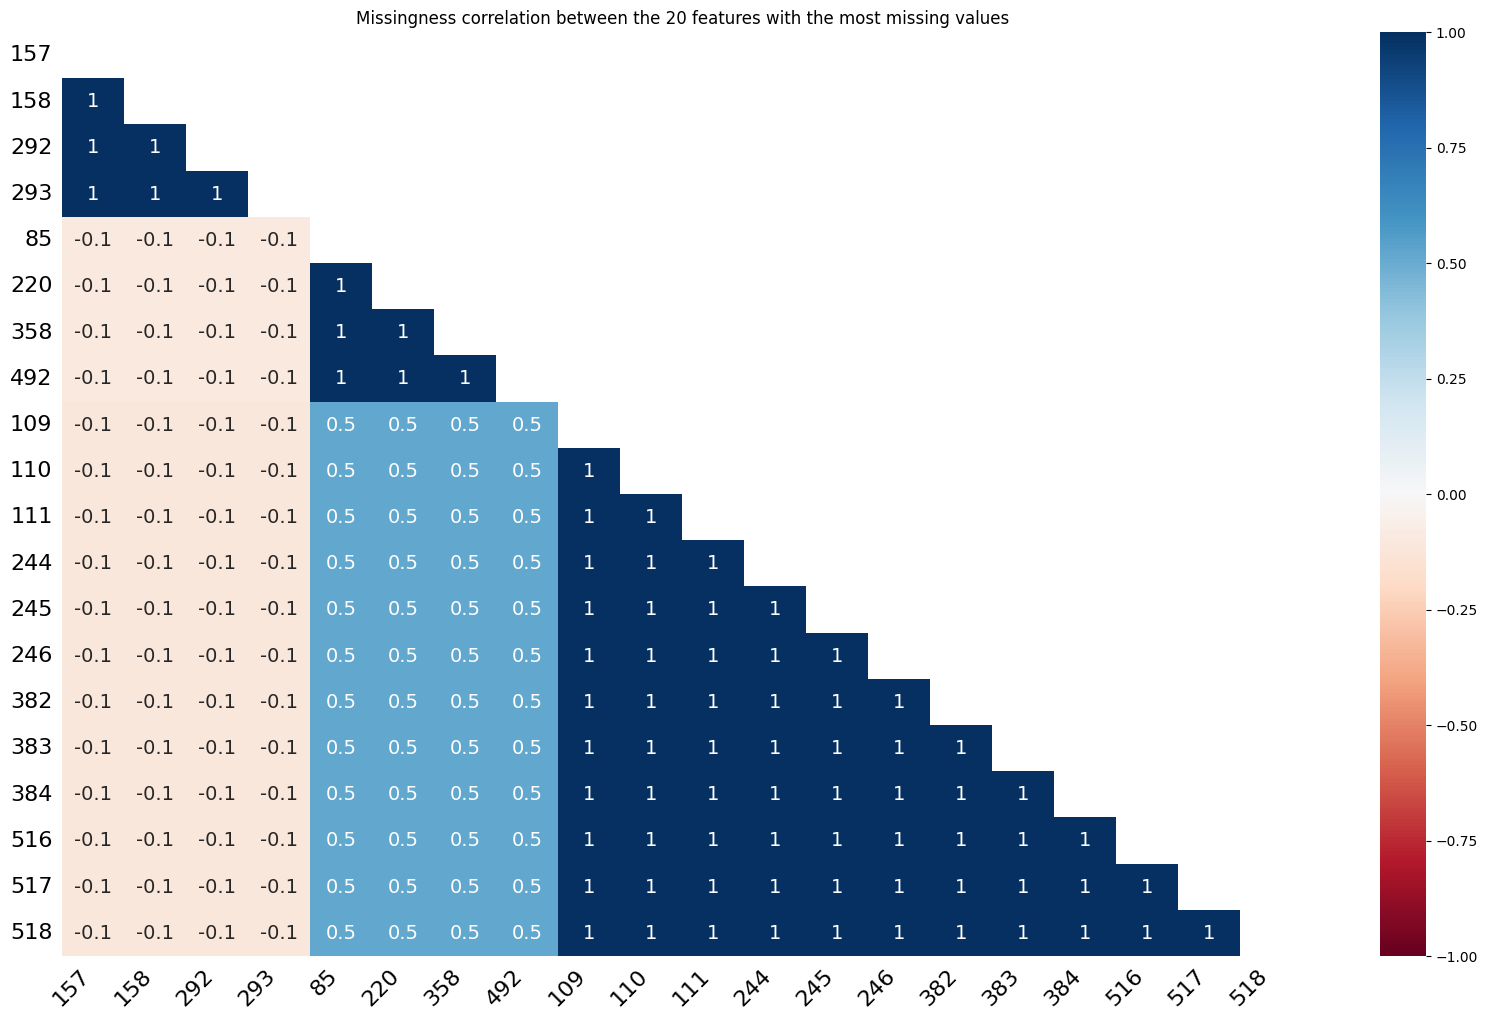

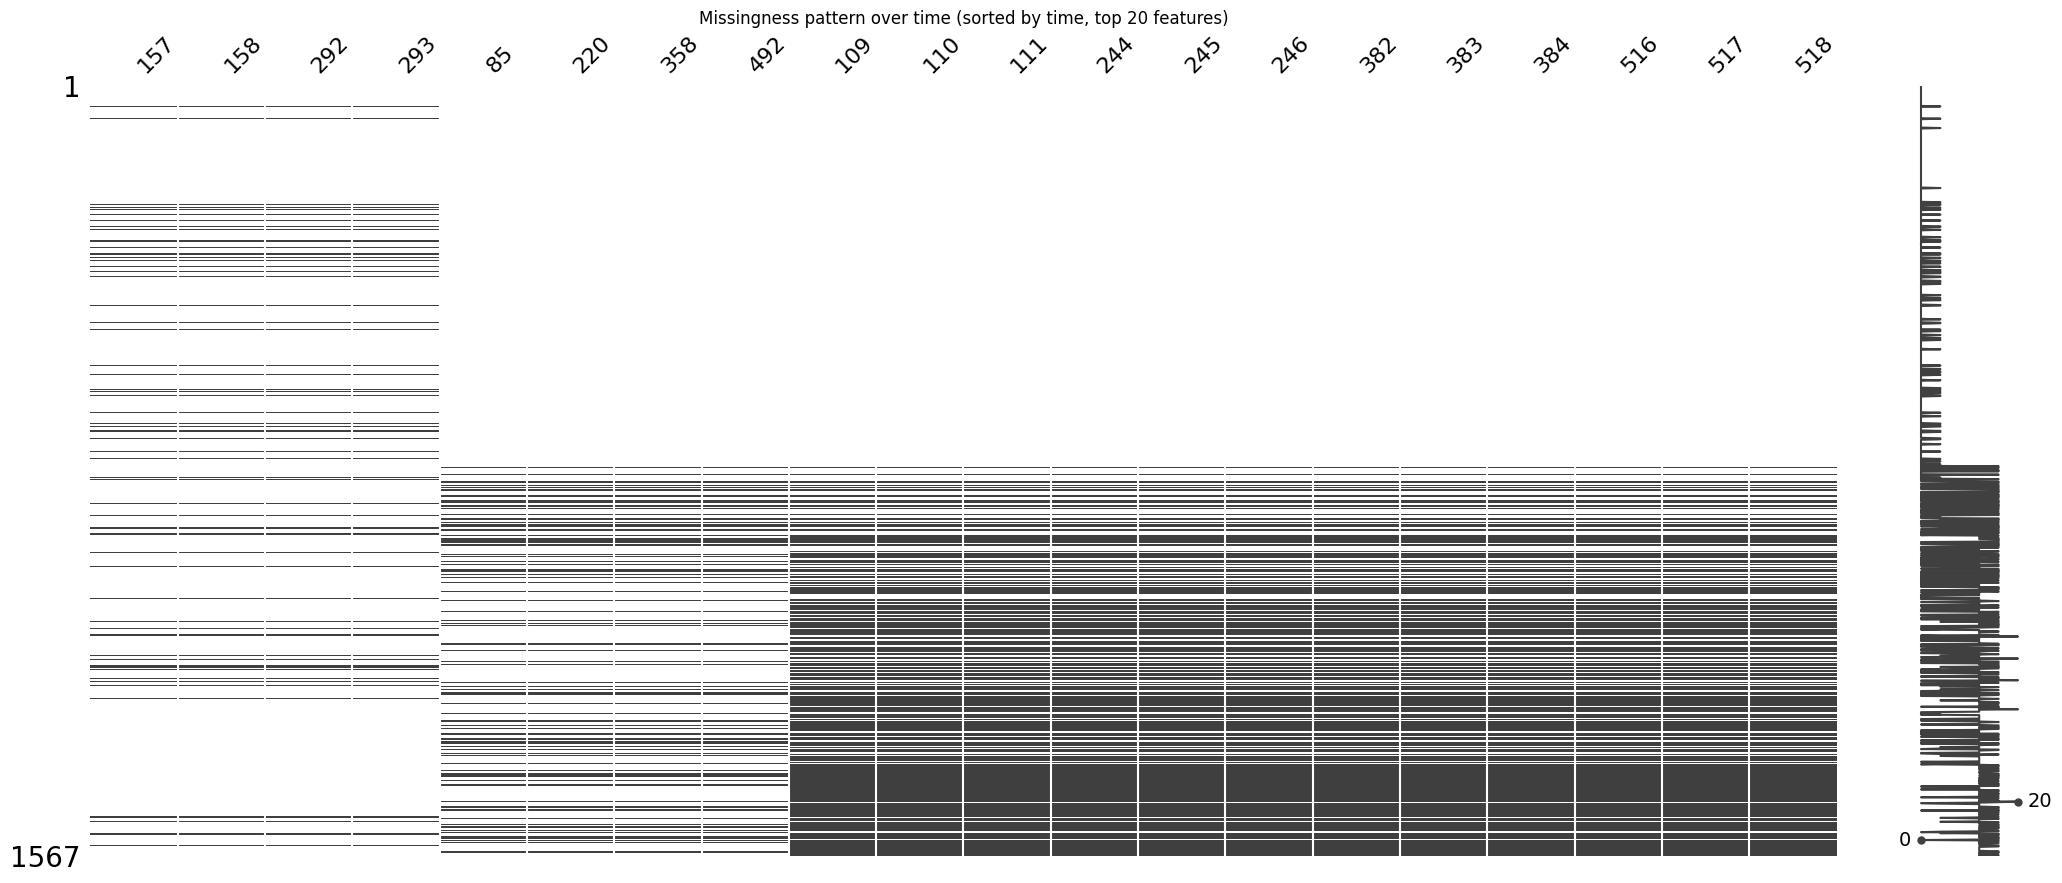

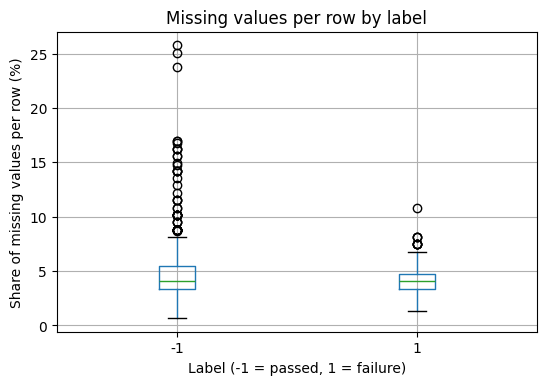

In [11]:
# Analyse the structure of the missingness

# Fixed top-N selection instead of a percentage cutoff: more robust against random gaps
# in the missing-value distribution and keeps the plots readable. This selection is for
# visualisation only, not for the later decision on the missing-value cutoff used in
# preprocessing (see below).
cols_with_missing = missing_pct.nlargest(20).index
print(f"Top {len(cols_with_missing)} features by share of missing values (for the missingness plots)")

# Co-missingness: which features are missing together?
msno.heatmap(sensors[cols_with_missing])
plt.title('Missingness correlation between the 20 features with the most missing values')
plt.show()

# Missingness matrix sorted by time: do missing values occur in temporal blocks?
msno.matrix(df.sort_values('timestamp')[cols_with_missing])
plt.title('Missingness pattern over time (sorted by time, top 20 features)')
plt.show()

# Row-level missingness by label: is the number of missing values per run related to the outcome?
# Separate small DataFrame instead of df.assign(), because df (592 columns, from pd.concat)
# is heavily fragmented and assign() would otherwise raise a PerformanceWarning.
row_missing_pct = sensors.isna().mean(axis=1) * 100
row_missing_df = pd.DataFrame({'row_missing_pct': row_missing_pct, 'label': df['label'].values})

fig, ax = plt.subplots(figsize=(6, 4))
row_missing_df.boxplot(column='row_missing_pct', by='label', ax=ax)
fig.suptitle('')
ax.set_title('Missing values per row by label')
ax.set_xlabel('Label (-1 = passed, 1 = failure)')
ax.set_ylabel('Share of missing values per row (%)')
plt.show()

### Relationship between features and failure status

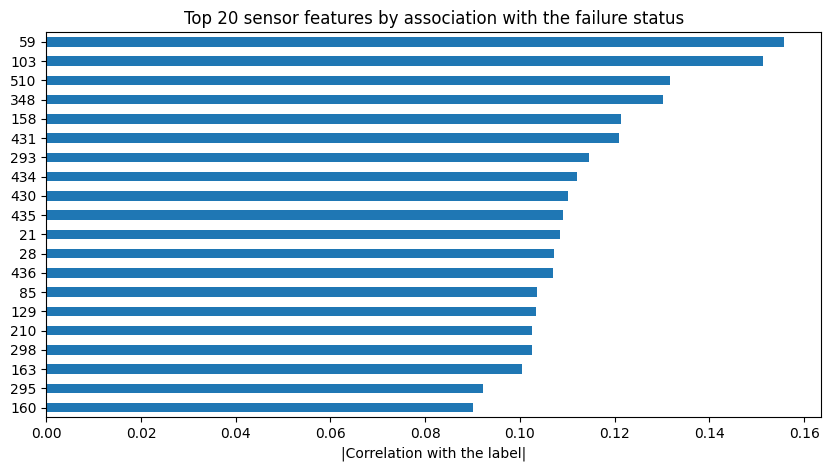

In [12]:
# Identify and visualise the most relevant sensor features
informative_sensors = sensors.drop(columns=low_info_cols)

feature_label_corr = {}
for col in informative_sensors.columns:
    valid = pd.DataFrame({'x': informative_sensors[col], 'y': df['label']}).dropna()
    if valid['x'].nunique() > 1:
        corr, _ = stats.pointbiserialr(valid['y'], valid['x'])
        feature_label_corr[col] = corr

feature_corr_ranked = pd.Series(feature_label_corr).abs().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
feature_corr_ranked.head(20).plot(kind='barh')
plt.gca().invert_yaxis()
plt.xlabel('|Correlation with the label|')
plt.title('Top 20 sensor features by association with the failure status')
plt.show()



### Class separability (principal component analysis)

Explained variance of PC1: 5.7%, PC2: 3.7%, total: 9.4%


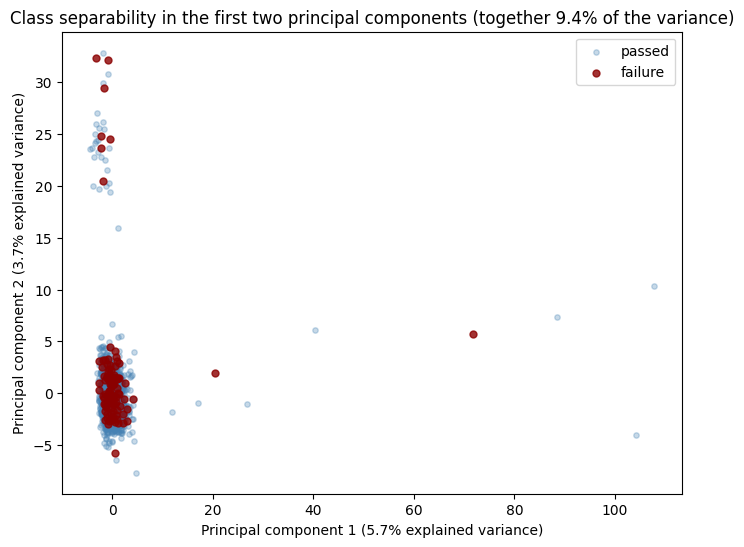

In [13]:
# Assess the basic class separability using principal component analysis (PCA)
X_pca_Input = SimpleImputer(strategy='median').fit_transform(informative_sensors)
X_pca_scaled = StandardScaler().fit_transform(X_pca_Input)
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_pca_scaled)

var_pc1, var_pc2 = pca.explained_variance_ratio_
print(f"Explained variance of PC1: {var_pc1:.1%}, PC2: {var_pc2:.1%}, total: {var_pc1 + var_pc2:.1%}")

# Plot by class so that the rare failure class does not disappear behind the dominant class
is_fail = df['label'] == 1

plt.figure(figsize=(8, 6))
plt.scatter(pcs[~is_fail, 0], pcs[~is_fail, 1], color='steelblue', alpha=0.3, label='passed', s=15)
plt.scatter(pcs[is_fail, 0], pcs[is_fail, 1], color='darkred', alpha=0.8, label='failure', s=25)
plt.xlabel(f'Principal component 1 ({var_pc1:.1%} explained variance)')
plt.ylabel(f'Principal component 2 ({var_pc2:.1%} explained variance)')
plt.title(f'Class separability in the first two principal components (together {var_pc1 + var_pc2:.1%} of the variance)')
plt.legend()
plt.show()

### Failure rate over time

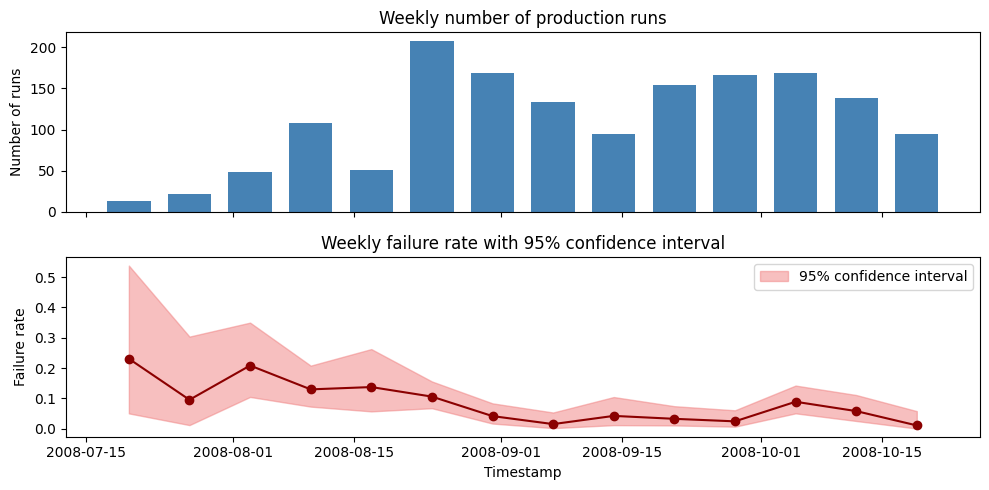

In [14]:
# Weekly failure rate with 95% confidence interval (binomial test) to make temporal
# variation of the class imbalance visible
weekly_failures = df.set_index('timestamp')['label'].resample('W').apply(lambda x: (x == 1).sum())
weekly_total = df.set_index('timestamp')['label'].resample('W').count()
weekly_failure_rate = weekly_failures / weekly_total

ci_lower, ci_upper = [], []
for k, n in zip(weekly_failures, weekly_total):
    lo, hi = stats.binomtest(int(k), int(n)).proportion_ci(confidence_level=0.95)
    ci_lower.append(lo)
    ci_upper.append(hi)

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

ax[0].bar(weekly_total.index, weekly_total.values, width=5, color='steelblue')
ax[0].set_ylabel('Number of runs')
ax[0].set_title('Weekly number of production runs')

ax[1].plot(weekly_failure_rate.index, weekly_failure_rate.values, marker='o', color='darkred')
ax[1].fill_between(weekly_failure_rate.index, ci_lower, ci_upper, color='lightcoral', alpha=0.5, label='95% confidence interval')
ax[1].set_ylabel('Failure rate')
ax[1].set_xlabel('Timestamp')
ax[1].set_title('Weekly failure rate with 95% confidence interval')
ax[1].legend()

plt.tight_layout()
plt.show()

## Preprocessing building blocks (custom transformers)

Reusable `scikit-learn` transformers for the later pipeline. They are only fitted after the train-test split so that no information from the test data leaks in.

In [15]:
class MissingThresholdSelector(BaseEstimator, TransformerMixin):
    """Removes features whose share of missing values exceeds the given threshold."""

    def __init__(self, missing_threshold=0.5):
        self.missing_threshold = missing_threshold
        self.kept_columns_ = None

    def fit(self, X, y=None):
        missing_share = X.isna().mean()
        self.kept_columns_ = missing_share[missing_share <= self.missing_threshold].index
        return self


    def transform(self, X):
        return X[self.kept_columns_]


class LowVarianceFeatureSelector(BaseEstimator, TransformerMixin):
    """Removes features with a coefficient of variation below the given threshold, as well as
    features with a mean of zero, for which the CV is undefined. For the latter, the standard
    deviation relative to the largest absolute value of the column is used instead (rather than
    a fixed absolute value), so that the criterion stays scale-invariant and consistent with the
    CV across the very different sensor scales."""

    def __init__(self, cv_threshold=0.01):
        self.cv_threshold = cv_threshold

    def fit(self, X, y=None):
        std = X.std()
        mean = X.mean()
        cv = (std / mean.abs()).replace([np.inf, -np.inf], np.nan)

        undefined_cv = cv[cv.isna()].index
        keep_by_cv = cv[cv >= self.cv_threshold].index
        relative_std = std.loc[undefined_cv] / X[undefined_cv].abs().max()
        keep_by_std = relative_std[relative_std >= self.cv_threshold].index

        self.kept_columns_ = keep_by_cv.union(keep_by_std)
        return self

    def transform(self, X):
        return X[self.kept_columns_]


class CorrelationFeatureSelector(BaseEstimator, TransformerMixin):
    """Removes features whose absolute point-biserial correlation with the binary
    target label is below the given threshold."""

    def __init__(self, correlation_threshold=0.01):
        self.correlation_threshold = correlation_threshold

    def fit(self, X, y):
        correlations = {}
        for col in X.columns:
            r, _ = stats.pointbiserialr(y, X[col])
            correlations[col] = abs(r)
        self.correlations_ = pd.Series(correlations)
        self.kept_columns_ = self.correlations_[self.correlations_ >= self.correlation_threshold].index
        return self

    def transform(self, X):
        return X[self.kept_columns_]
        


    

## Train-test split

In [16]:
# Split into training and test data (80% training, 20% test)
# Chronological split (no shuffle): the test data are the later runs, matching the question
# "predict future runs from past data". stratify is therefore not possible (it requires
# shuffling), so the failure rate in train/test is reported explicitly below.

df_sorted = df.sort_values('timestamp').reset_index(drop=True)

X = df_sorted.drop(columns=['label', 'timestamp'])
y = df_sorted['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False, random_state=SEED)

print(f"Training data: {X_train.shape[0]} rows, {X_train.shape[1]} columns")
print(f"Test data: {X_test.shape[0]} rows, {X_test.shape[1]} columns")
print(f"Failure rate (training): {(y_train == 1).mean():.2%}")
print(f"Failure rate (test): {(y_test == 1).mean():.2%}")

Training data: 1253 rows, 590 columns
Test data: 314 rows, 590 columns
Failure rate (training): 6.94%
Failure rate (test): 5.41%


## Data preparation (preprocessing pipeline)

All label-dependent steps (correlation filter, threshold search) as well as the fitting of filters, imputer and scaler are performed exclusively on the training data (`fit`) and only applied to the test data (`transform`) to avoid data leakage. The thresholds for the share of missing values (30 %) and the coefficient of variation (1 %) were set in the exploratory analysis on the full dataset without using the label.

### Handling missing values and low variability

In [17]:
# Handling missing values
# The 30% cutoff is based on the gap analysis above (cell with sorted_missing/gaps): the
# largest jump in the sorted distribution of missing values lies between 17.4% and 45.6%,
# so a cutoff of 30% separates cleanly there. Important: filter and imputer are only fitted
# on X_train and only applied to X_test (no data leakage).
# Each pipeline stage gets its own variable name (X_train_imp, X_train_var, ...) instead of
# overwriting X_train/X_test in place, so every cell stays independently reproducible, even
# when re-run out of the original order.

missing_filter = MissingThresholdSelector(missing_threshold=0.3)
X_train_imp = missing_filter.fit_transform(X_train)
X_test_imp = missing_filter.transform(X_test)
print(f"Columns after missing-value filter: {X_train_imp.shape[1]} of originally 590")

imputer = SimpleImputer(strategy='median')
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train_imp), columns=X_train_imp.columns, index=X_train_imp.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test_imp), columns=X_test_imp.columns, index=X_test_imp.index)

print(f"Remaining missing values – training: {X_train_imp.isna().sum().sum()}, test: {X_test_imp.isna().sum().sum()}")

Columns after missing-value filter: 558 of originally 590
Remaining missing values – training: 0, test: 0


In [18]:
# Remove constant/quasi-constant features (fitted on X_train only)
# X_train_var/X_test_var stay unscaled and are used directly as the feature set for
# gradient boosting further below (see the rationale there).
selector = LowVarianceFeatureSelector(cv_threshold=0.01)
X_train_var = selector.fit_transform(X_train_imp)
X_test_var = selector.transform(X_test_imp)
print(f"Columns after low-variance filter: {X_train_var.shape[1]} of {X_train_imp.shape[1]}")

Columns after low-variance filter: 421 of 558


### Feature selection by correlation with the label

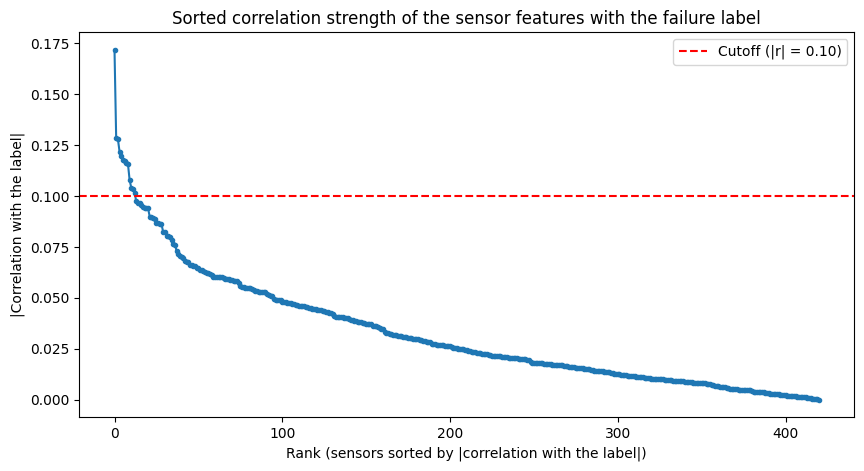

Top 10 ranks with the largest jump relative to the previous value:
1     0.043561
9     0.007903
3     0.006254
21    0.004069
13    0.003990
10    0.003982
29    0.003962
37    0.003035
4     0.002281
35    0.002038
dtype: float64


In [19]:
# Determine a cutoff for the correlation with the label to identify the most relevant sensor features

diagnostic_selector = CorrelationFeatureSelector(correlation_threshold=0)
diagnostic_selector.fit(X_train_var, y_train)

sorted_corr = diagnostic_selector.correlations_.sort_values(ascending=False).reset_index(drop=True)
gaps = sorted_corr.diff().abs()

plt.figure(figsize=(10, 5))
plt.plot(sorted_corr.values, marker='o', markersize=3)
plt.axhline(0.1, color='red', linestyle='--', label='Cutoff (|r| = 0.10)')
plt.xlabel('Rank (sensors sorted by |correlation with the label|)')
plt.ylabel('|Correlation with the label|')
plt.title('Sorted correlation strength of the sensor features with the failure label')
plt.legend()
plt.show()

print("Top 10 ranks with the largest jump relative to the previous value:")
print(gaps.nlargest(10))

In [20]:
# Apply the correlation filter with the cutoff determined above
# Unlike for the missing-value cutoff, there is no single dominant jump here: the largest
# jump lies between the strongest sensor and the rest (which would leave only 1 feature),
# after which the correlation decreases fairly evenly. 0.10 keeps the comparatively more
# strongly correlated sensors without reducing the set to a single outlier.
# This filter is deliberately used for logistic regression only (X_train_corr/X_test_corr):
# it selects by point-biserial, i.e. linear/monotonic correlation with the label. Gradient
# boosting instead gets the larger X_train_var/X_test_var further below, which are not
# pre-filtered linearly, so that a tree model is not deprived of potentially non-linear
# relationships by a purely linear criterion.

corr_selector = CorrelationFeatureSelector(correlation_threshold=0.1)
X_train_corr = corr_selector.fit_transform(X_train_var, y_train)
X_test_corr = corr_selector.transform(X_test_var)
print(f"Columns after correlation filter: {X_train_corr.shape[1]} of {len(diagnostic_selector.correlations_)}")

Columns after correlation filter: 13 of 421


In [21]:
# Overview of the filter cascade: remaining and removed features per step

filter_cascade = pd.DataFrame({
    'Step': ['Raw data', 'Missing-value filter (30%)', 'Variability filter (CV 1%)', 'Correlation filter (|r| ≥ 0.10)'],
    'Remaining features': [X_train.shape[1], X_train_imp.shape[1], X_train_var.shape[1], X_train_corr.shape[1]],
})
filter_cascade['Removed features'] = filter_cascade['Remaining features'].shift(1) - filter_cascade['Remaining features']
filter_cascade.loc[0, 'Removed features'] = 0
filter_cascade['Removed features'] = filter_cascade['Removed features'].astype(int)
filter_cascade

,Step,Remaining features,Removed features
0,Raw data,590,0
1,Missing-value filter (30%),558,32
2,Variability filter (CV 1%),421,137
3,Correlation filter (|r| ≥ 0.10),13,408


## Model training and comparison of different strategies

### Reference model: logistic regression (balanced)

In [22]:
# Prediction using regularised logistic regression
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_corr), columns=X_train_corr.columns, index=X_train_corr.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_corr), columns=X_test_corr.columns, index=X_test_corr.index) 

log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEED).fit(X_train_scaled, y_train)

log_reg.score(X_test_scaled, y_test)

0.8789808917197452

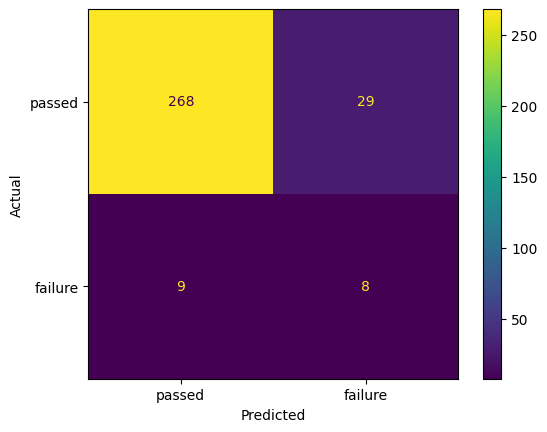

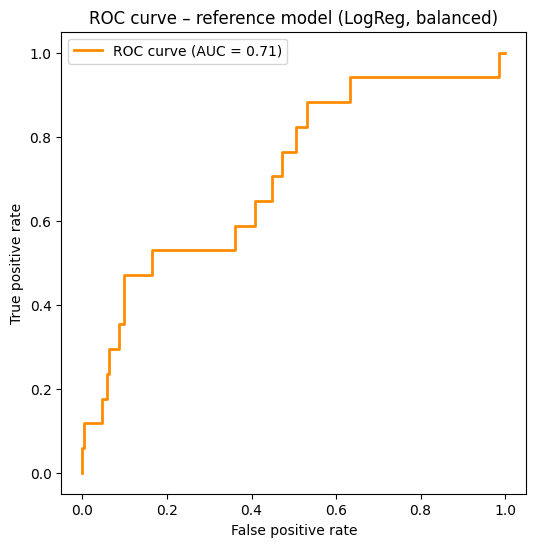

              precision    recall  f1-score   support

      passed       0.97      0.90      0.93       297
     failure       0.22      0.47      0.30        17

    accuracy                           0.88       314
   macro avg       0.59      0.69      0.62       314
weighted avg       0.93      0.88      0.90       314

Matthews correlation coefficient: 0.262


In [23]:
# Visualise the results of the logistic regression using a confusion matrix and ROC curve

# Create a confusion matrix
cm_log_reg = confusion_matrix(y_test, log_reg.predict(X_test_scaled))
disp_log_reg = ConfusionMatrixDisplay(confusion_matrix=cm_log_reg, display_labels=['passed', 'failure'])
ax_cm_log_reg = disp_log_reg.plot().ax_
ax_cm_log_reg.set_xlabel('Predicted')
ax_cm_log_reg.set_ylabel('Actual')
ax_cm_log_reg.grid(False)

# Compute the ROC curve and AUC and visualise them
y_scores_log_reg = log_reg.decision_function(X_test_scaled)
fpr_log_reg, tpr_log_reg, thresholds_log_reg = roc_curve(y_test, y_scores_log_reg)
roc_auc_log_reg = auc(fpr_log_reg, tpr_log_reg)

plt.figure(figsize=(6, 6))
plt.plot(fpr_log_reg, tpr_log_reg, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_log_reg:.2f})')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve – reference model (LogReg, balanced)')
plt.legend()
plt.show()

print(classification_report(y_test, log_reg.predict(X_test_scaled), target_names=['passed', 'failure']))
print(f'Matthews correlation coefficient: {matthews_corrcoef(y_test, log_reg.predict(X_test_scaled)):.3f}')

### Comparison model: gradient boosting (balanced)

In [24]:
# Prediction using a gradient boosting classifier
# Deliberately trained on X_train_var/X_test_var (variance-filtered, but without the linear
# correlation filter and without scaling, see the comment at the filter step above): tree
# models are scale-invariant and, unlike logistic regression, can exploit non-linear
# relationships in the additional features.
gb_classifier = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=SEED)
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
sample_weight = np.where(y_train == 1, class_weights[1], class_weights[0])

gb_classifier.fit(X_train_var, y_train, sample_weight=sample_weight)
gb_classifier.predict(X_test_var)  

array([-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1,  1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1,  1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1,  1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1

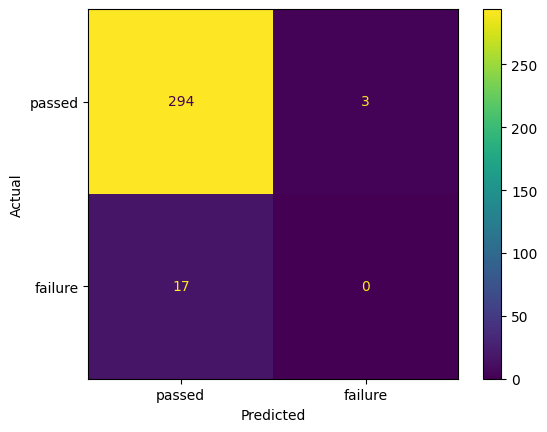

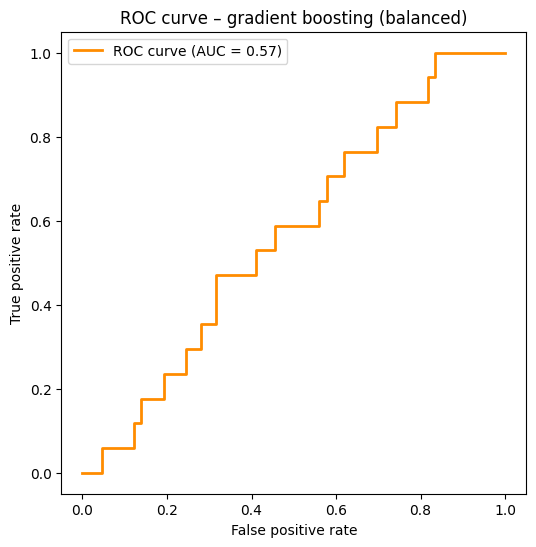

              precision    recall  f1-score   support

      passed       0.95      0.99      0.97       297
     failure       0.00      0.00      0.00        17

    accuracy                           0.94       314
   macro avg       0.47      0.49      0.48       314
weighted avg       0.89      0.94      0.91       314

Matthews correlation coefficient: -0.023


In [25]:
# Visualise the results of the gradient boosting classifier using a confusion matrix and ROC curve

# Create a confusion matrix
cm_gb = confusion_matrix(y_test, gb_classifier.predict(X_test_var))
disp_gb = ConfusionMatrixDisplay(confusion_matrix=cm_gb, display_labels=['passed', 'failure'])
ax_cm_gb = disp_gb.plot().ax_
ax_cm_gb.set_xlabel('Predicted')
ax_cm_gb.set_ylabel('Actual')
ax_cm_gb.grid(False)

# Compute the ROC curve and AUC and visualise them
y_scores_gb = gb_classifier.decision_function(X_test_var)
fpr_gb, tpr_gb, thresholds_gb = roc_curve(y_test, y_scores_gb)
roc_auc_gb = auc(fpr_gb, tpr_gb)

plt.figure(figsize=(6, 6))
plt.plot(fpr_gb, tpr_gb, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_gb:.2f})')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve – gradient boosting (balanced)')
plt.legend()
plt.show()

print(classification_report(y_test, gb_classifier.predict(X_test_var), target_names=['passed', 'failure']))
print(f'Matthews correlation coefficient: {matthews_corrcoef(y_test, gb_classifier.predict(X_test_var)):.3f}')

### Handling the class imbalance with SMOTE

In [26]:
# Add SMOTE to address the class imbalance
# Separate resampling per model branch, since logistic regression and gradient boosting
# now use different feature sets (X_train_scaled vs. X_train_var).
smote = SMOTE(random_state=SEED)
X_train_scaled_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)
print(f"Training data after SMOTE (LogReg branch): {X_train_scaled_smote.shape[0]} rows, {X_train_scaled_smote.shape[1]} columns")
print(f"Failure rate after SMOTE: {(y_train_smote == 1).mean():.2%}")
print(f"Class distribution (LogReg branch): {y_train_smote.value_counts().to_dict()}")

smote_tree = SMOTE(random_state=SEED)
X_train_var_smote, y_train_var_smote = smote_tree.fit_resample(X_train_var, y_train)
print(f"Training data after SMOTE (GB branch): {X_train_var_smote.shape[0]} rows, {X_train_var_smote.shape[1]} columns")
print(f"Failure rate after SMOTE: {(y_train_var_smote == 1).mean():.2%}")
print(f"Class distribution (GB branch): {y_train_var_smote.value_counts().to_dict()}")

Training data after SMOTE (LogReg branch): 2332 rows, 13 columns
Failure rate after SMOTE: 50.00%
Class distribution (LogReg branch): {-1: 1166, 1: 1166}
Training data after SMOTE (GB branch): 2332 rows, 421 columns
Failure rate after SMOTE: 50.00%
Class distribution (GB branch): {-1: 1166, 1: 1166}


In [27]:
# Logistic regression after SMOTE
log_reg_smote = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEED).fit(X_train_scaled_smote, y_train_smote)
log_reg_smote.predict(X_test_scaled)   


array([ 1,  1, -1,  1,  1, -1, -1, -1,  1,  1,  1,  1,  1,  1, -1, -1, -1,
       -1, -1, -1,  1,  1,  1,  1,  1,  1, -1, -1, -1, -1,  1, -1, -1, -1,
       -1, -1, -1, -1, -1,  1, -1, -1, -1, -1,  1, -1, -1, -1, -1, -1,  1,
       -1, -1, -1,  1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1,  1,  1,  1,  1, -1, -1, -1, -1, -1, -1, -1,  1, -1,
       -1, -1, -1, -1, -1, -1,  1, -1, -1, -1, -1, -1, -1,  1, -1,  1, -1,
       -1,  1, -1, -1, -1, -1, -1, -1, -1,  1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1,  1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1,  1, -1, -1, -1, -1, -1, -1,  1, -1, -1,  1, -1, -1, -1, -1, -1,
       -1, -1,  1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,  1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1,  1, -1, -1, -1, -1, -1, -1,  1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1

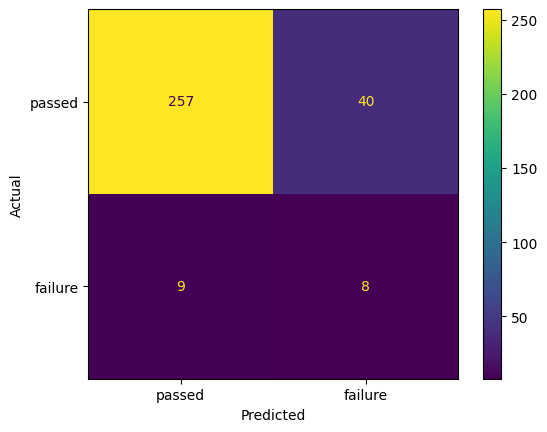

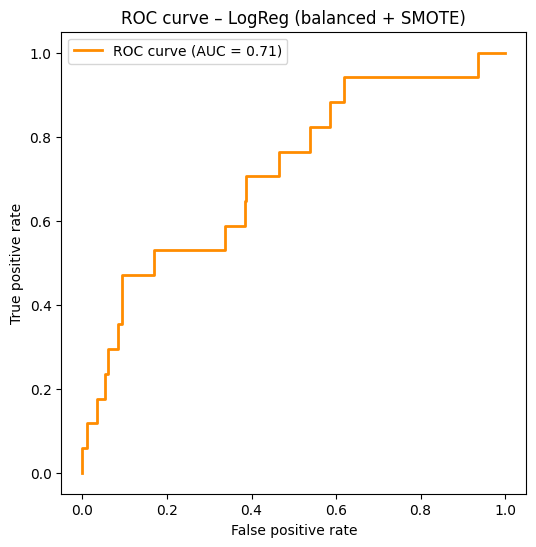

              precision    recall  f1-score   support

      passed       0.97      0.87      0.91       297
     failure       0.17      0.47      0.25        17

    accuracy                           0.84       314
   macro avg       0.57      0.67      0.58       314
weighted avg       0.92      0.84      0.88       314

Matthews correlation coefficient: 0.211


In [28]:
# Visualise the results of the logistic regression after SMOTE using a confusion matrix and ROC curve

# Create a confusion matrix
cm_log_reg_smote = confusion_matrix(y_test, log_reg_smote.predict(X_test_scaled))
disp_log_reg_smote = ConfusionMatrixDisplay(confusion_matrix=cm_log_reg_smote, display_labels=['passed', 'failure'])
ax_cm_log_reg_smote = disp_log_reg_smote.plot().ax_
ax_cm_log_reg_smote.set_xlabel('Predicted')
ax_cm_log_reg_smote.set_ylabel('Actual')
ax_cm_log_reg_smote.grid(False)

# Compute the ROC curve and AUC and visualise them
y_scores_log_reg_smote = log_reg_smote.decision_function(X_test_scaled)
fpr_log_reg_smote, tpr_log_reg_smote, thresholds_log_reg_smote = roc_curve(y_test, y_scores_log_reg_smote)
roc_auc_log_reg_smote = auc(fpr_log_reg_smote, tpr_log_reg_smote)

plt.figure(figsize=(6, 6))
plt.plot(fpr_log_reg_smote, tpr_log_reg_smote, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_log_reg_smote:.2f})')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve – LogReg (balanced + SMOTE)')
plt.legend()
plt.show()

print(classification_report(y_test, log_reg_smote.predict(X_test_scaled), target_names=['passed', 'failure']))
print(f'Matthews correlation coefficient: {matthews_corrcoef(y_test, log_reg_smote.predict(X_test_scaled)):.3f}')

In [29]:
# Gradient boosting classifier after SMOTE
gb_classifier_smote = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=SEED)
class_weights_smote = compute_class_weight('balanced', classes=np.unique(y_train_var_smote), y=y_train_var_smote)
sample_weight_smote = np.where(y_train_var_smote == 1, class_weights_smote[1], class_weights_smote[0])

gb_classifier_smote.fit(X_train_var_smote, y_train_var_smote, sample_weight=sample_weight_smote)
gb_classifier_smote.predict(X_test_var)

array([-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1,  1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1,  1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1

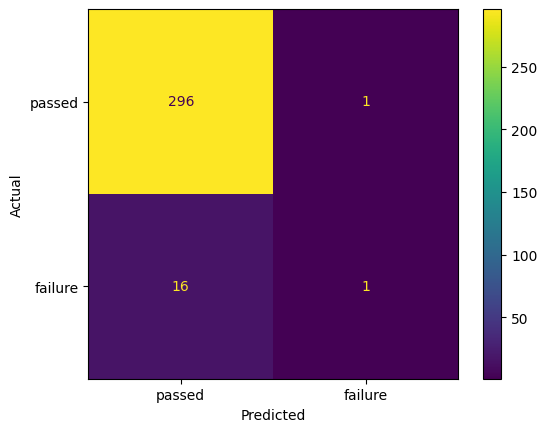

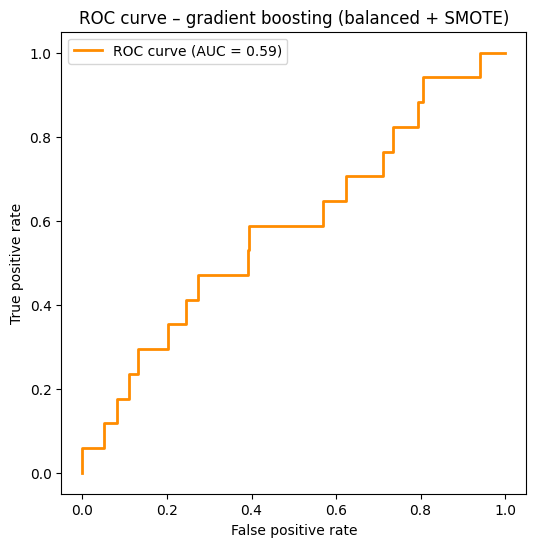

              precision    recall  f1-score   support

      passed       0.95      1.00      0.97       297
     failure       0.50      0.06      0.11        17

    accuracy                           0.95       314
   macro avg       0.72      0.53      0.54       314
weighted avg       0.92      0.95      0.93       314

Matthews correlation coefficient: 0.158


In [30]:
# Visualise the results of the gradient boosting classifier after SMOTE using a confusion matrix and ROC curve

# Create a confusion matrix
cm_gb_smote = confusion_matrix(y_test, gb_classifier_smote.predict(X_test_var))
disp_gb_smote = ConfusionMatrixDisplay(confusion_matrix=cm_gb_smote, display_labels=['passed', 'failure'])
ax_cm_gb_smote = disp_gb_smote.plot().ax_
ax_cm_gb_smote.set_xlabel('Predicted')
ax_cm_gb_smote.set_ylabel('Actual')
ax_cm_gb_smote.grid(False)

# Compute the ROC curve and AUC and visualise them
y_scores_gb_smote = gb_classifier_smote.decision_function(X_test_var)
fpr_gb_smote, tpr_gb_smote, thresholds_gb_smote = roc_curve(y_test, y_scores_gb_smote)
roc_auc_gb_smote = auc(fpr_gb_smote, tpr_gb_smote)

plt.figure(figsize=(6, 6))
plt.plot(fpr_gb_smote, tpr_gb_smote, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_gb_smote:.2f})')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve – gradient boosting (balanced + SMOTE)')
plt.legend()
plt.show()

print(classification_report(y_test, gb_classifier_smote.predict(X_test_var), target_names=['passed', 'failure']))
print(f'Matthews correlation coefficient: {matthews_corrcoef(y_test, gb_classifier_smote.predict(X_test_var)):.3f}')

### Adjusting the decision threshold

Optimal decision threshold based on MCC: 0.525


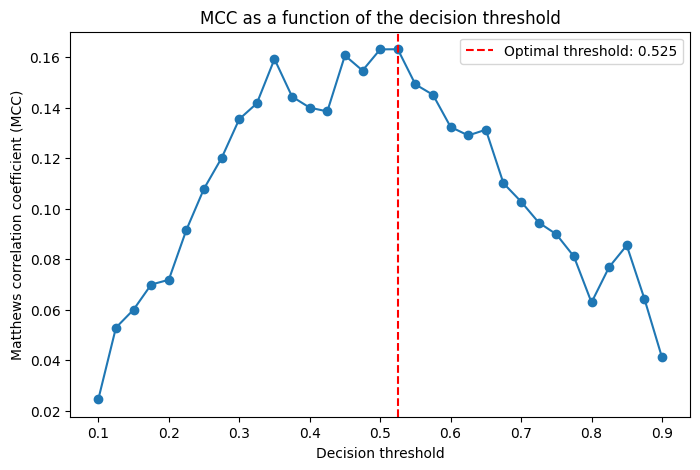

              precision    recall  f1-score   support

      passed       0.96      0.91      0.94       297
     failure       0.19      0.35      0.24        17

    accuracy                           0.88       314
   macro avg       0.57      0.63      0.59       314
weighted avg       0.92      0.88      0.90       314

Matthews correlation coefficient: 0.199


In [31]:
# Adjust the decision threshold for the logistic regression (balanced, without SMOTE) by optimising the threshold for the MCC.
log_reg_base = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEED)
oof_preds = cross_val_predict(log_reg_base, X_train_scaled, y_train, cv=5, method='predict_proba')[:, 1]

thresholds = np.linspace(0.1, 0.9, 33)
mcc_scores = [matthews_corrcoef(y_train, (oof_preds >= t).astype(int) * 2 - 1) for t in thresholds]

best_threshold = thresholds[np.argmax(mcc_scores)]
print(f"Optimal decision threshold based on MCC: {best_threshold:.3f}")

plt.figure(figsize=(8, 5))
plt.plot(thresholds, mcc_scores, marker='o')
plt.axvline(best_threshold, color='red', linestyle='--', label=f'Optimal threshold: {best_threshold:.3f}')
plt.title('MCC as a function of the decision threshold')
plt.xlabel('Decision threshold')
plt.ylabel('Matthews correlation coefficient (MCC)')
plt.legend()
plt.show()

log_reg_final = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEED).fit(X_train_scaled, y_train)
test_probs_final = log_reg_final.predict_proba(X_test_scaled)[:, 1]
y_pred_final_threshold = np.where(test_probs_final >= best_threshold, 1, -1)

print(classification_report(y_test, y_pred_final_threshold, target_names=['passed', 'failure']))
print(f'Matthews correlation coefficient: {matthews_corrcoef(y_test, y_pred_final_threshold):.3f}')

### Summary model comparison

In [32]:
# Summary comparison of the results
# F1, MCC, AUC, precision, recall and accuracy are computed live from the currently trained
# models (no longer hard-coded), so the table stays correct after changes to the upstream
# pipeline (e.g. the correlation filter).
# The dashboard only uses the columns 'F1 (failure)', 'MCC' and 'ROC-AUC' and is unaffected
# by the additional columns.

preds_by_model = {
    'LogReg (balanced)': log_reg.predict(X_test_scaled),
    'LogReg (balanced + SMOTE)': log_reg_smote.predict(X_test_scaled),
    'LogReg (balanced + threshold)': y_pred_final_threshold,
    'GB (balanced)': gb_classifier.predict(X_test_var),
    'GB (balanced + SMOTE)': gb_classifier_smote.predict(X_test_var),
}

comparison = pd.DataFrame({
    'Model': list(preds_by_model.keys()),
    'F1 (failure)': [f1_score(y_test, p, pos_label=1) for p in preds_by_model.values()],
    'MCC': [matthews_corrcoef(y_test, p) for p in preds_by_model.values()],
    'ROC-AUC': [roc_auc_log_reg, roc_auc_log_reg_smote, roc_auc_log_reg, roc_auc_gb, roc_auc_gb_smote],
    'Precision (failure)': [precision_score(y_test, p, pos_label=1, zero_division=0) for p in preds_by_model.values()],
    'Recall (failure)': [recall_score(y_test, p, pos_label=1, zero_division=0) for p in preds_by_model.values()],
    'Accuracy': [accuracy_score(y_test, p) for p in preds_by_model.values()],
})
comparison

,Model,F1 (failure),MCC,ROC-AUC,Precision (failure),Recall (failure),Accuracy
0,LogReg (balanced),0.296296,0.261762,0.708061,0.216216,0.470588,0.878981
1,LogReg (balanced + SMOTE),0.246154,0.211233,0.714597,0.166667,0.470588,0.843949
2,LogReg (balanced + threshold),0.244898,0.198519,0.708061,0.187500,0.352941,0.882166
3,GB (balanced),0.000000,-0.023498,0.566449,0.000000,0.000000,0.936306
4,GB (balanced + SMOTE),0.105263,0.157748,0.585066,0.500000,0.058824,0.945860


### The 13 selected features

Feature number (column index, 0-based, as in the raw file `secom.data`), signed point-biserial correlation with the label and coefficient of the logistic regression, sorted by |correlation|.

In [33]:
# Feature number, signed correlation with the label and logistic regression coefficient
# for the 13 selected features.

coef_series = pd.Series(log_reg.coef_[0], index=X_train_scaled.columns)

signed_corr = {}
for col in X_train_corr.columns:
    r, _ = stats.pointbiserialr(y_train, X_train_corr[col])
    signed_corr[col] = r

table7 = pd.DataFrame({
    'Feature number (0-based)': list(signed_corr.keys()),
    'Correlation with label (r)': list(signed_corr.values()),
    'Model coefficient': coef_series.loc[list(signed_corr.keys())].values,
})
table7 = table7.reindex(table7['Correlation with label (r)'].abs().sort_values(ascending=False).index).reset_index(drop=True)
table7

,Feature number (0-based),Correlation with label (r),Model coefficient
0,59,0.171785,0.598732
1,103,0.128224,0.098618
2,431,0.128080,0.330361
3,510,0.121826,0.161373
4,430,0.119545,0.095048
5,434,0.117703,0.396542
6,21,0.117205,0.621654
7,435,0.116146,-0.739186
8,436,0.115836,-0.283616
9,129,0.107933,0.416596


## Statistical robustness and additional analyses

Supplementary analyses to back up the results reported above: bootstrap confidence intervals for the key performance metrics, an ablation of the feature sets to separate model type effects from feature effects, a cost comparison of the decision strategies, and a diagnostic on the independence of the preprocessing thresholds from the test set.

### Bootstrap confidence intervals for MCC and F1

In [34]:
# Bootstrap confidence intervals (2000 draws with replacement from the test set)
# for MCC and F1, for all five model variants. Paired resampling (same row indices
# for all variants in each draw), so that the draws can also be used below for the
# direct comparison (reference vs. other variant).

import warnings

n_boot = 2000
rng = np.random.RandomState(SEED)
y_test_arr = y_test.to_numpy()
n_test = len(y_test_arr)

boot_mcc = {name: np.empty(n_boot) for name in preds_by_model}
boot_f1 = {name: np.empty(n_boot) for name in preds_by_model}

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for b in range(n_boot):
        idx = rng.randint(0, n_test, n_test)
        y_b = y_test_arr[idx]
        for name, preds in preds_by_model.items():
            p_b = preds[idx]
            boot_mcc[name][b] = matthews_corrcoef(y_b, p_b)
            boot_f1[name][b] = f1_score(y_b, p_b, pos_label=1, zero_division=0)

bootstrap_summary = pd.DataFrame({
    'Model': list(preds_by_model.keys()),
    'MCC (point estimate)': [matthews_corrcoef(y_test, preds_by_model[m]) for m in preds_by_model],
    'MCC 95%-CI': [f"[{np.percentile(boot_mcc[m], 2.5):.3f}, {np.percentile(boot_mcc[m], 97.5):.3f}]" for m in preds_by_model],
    'F1 (point estimate)': [f1_score(y_test, preds_by_model[m], pos_label=1) for m in preds_by_model],
    'F1 95%-CI': [f"[{np.percentile(boot_f1[m], 2.5):.3f}, {np.percentile(boot_f1[m], 97.5):.3f}]" for m in preds_by_model],
})
bootstrap_summary

,Model,MCC (point estimate),MCC 95%-CI,F1 (point estimate),F1 95%-CI
0,LogReg (balanced),0.261762,"[0.091, 0.424]",0.296296,"[0.133, 0.444]"
1,LogReg (balanced + SMOTE),0.211233,"[0.057, 0.361]",0.246154,"[0.109, 0.373]"
2,LogReg (balanced + threshold),0.198519,"[0.028, 0.367]",0.244898,"[0.087, 0.393]"
3,GB (balanced),-0.023498,"[-0.036, 0.000]",0.000000,"[0.000, 0.000]"
4,GB (balanced + SMOTE),0.157748,"[-0.022, 0.398]",0.105263,"[0.000, 0.316]"


In [35]:
# Feasibility criterion 1: how often is the reference (LogReg balanced) better than the
# other variants in joint (paired) draws?

reference = 'LogReg (balanced)'
others = [n for n in preds_by_model if n != reference]

win_rates_mcc = {n: (boot_mcc[reference] > boot_mcc[n]).mean() for n in others}
win_rates_f1 = {n: (boot_f1[reference] > boot_f1[n]).mean() for n in others}

other_mcc_matrix = np.vstack([boot_mcc[n] for n in others])
other_f1_matrix = np.vstack([boot_f1[n] for n in others])
win_best_mcc = (boot_mcc[reference] > other_mcc_matrix.max(axis=0)).mean()
win_best_f1 = (boot_f1[reference] > other_f1_matrix.max(axis=0)).mean()

print(f"Share of joint draws in which the reference ({reference}) is better than ...")
for n in others:
    print(f"  ... {n}: MCC {win_rates_mcc[n]:.1%}, F1 {win_rates_f1[n]:.1%}")
print(f"  ... ALL other variants simultaneously: MCC {win_best_mcc:.1%}, F1 {win_best_f1:.1%}")

Share of joint draws in which the reference (LogReg (balanced)) is better than ...
  ... LogReg (balanced + SMOTE): MCC 100.0%, F1 100.0%
  ... LogReg (balanced + threshold): MCC 85.2%, F1 84.5%
  ... GB (balanced): MCC 100.0%, F1 100.0%
  ... GB (balanced + SMOTE): MCC 79.2%, F1 95.6%
  ... ALL other variants simultaneously: MCC 69.7%, F1 81.7%


### Ablation of the feature sets

Separates the effect of the model type from the effect of the feature set: logistic regression on the 421 (low-variance) features and gradient boosting on the 13 (correlation) features, i.e. in each case the feature set of the *other* model from the main comparison.

In [36]:
# Ablation of the feature sets: logistic regression on the 421 low-variance features and
# gradient boosting on the 13 correlation features, each with the same hyperparameters and
# class weights as in the main comparison. Answers whether the differences observed there
# are due to the model type or to the feature set.

scaler_421 = StandardScaler()
X_train_var_scaled = pd.DataFrame(scaler_421.fit_transform(X_train_var), columns=X_train_var.columns, index=X_train_var.index)
X_test_var_scaled = pd.DataFrame(scaler_421.transform(X_test_var), columns=X_test_var.columns, index=X_test_var.index)

log_reg_421 = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEED).fit(X_train_var_scaled, y_train)
pred_log_reg_421 = log_reg_421.predict(X_test_var_scaled)
auc_log_reg_421 = auc(*roc_curve(y_test, log_reg_421.decision_function(X_test_var_scaled))[:2])

class_weights_13 = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
sample_weight_13 = np.where(y_train == 1, class_weights_13[1], class_weights_13[0])
gb_13 = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=SEED)
gb_13.fit(X_train_corr, y_train, sample_weight=sample_weight_13)
pred_gb_13 = gb_13.predict(X_test_corr)
auc_gb_13 = auc(*roc_curve(y_test, gb_13.decision_function(X_test_corr))[:2])

ablation = pd.DataFrame({
    'Variant': ['LogReg (balanced) on 421 features', 'GB (balanced) on 13 features'],
    'F1 (failure)': [f1_score(y_test, pred_log_reg_421, pos_label=1), f1_score(y_test, pred_gb_13, pos_label=1)],
    'MCC': [matthews_corrcoef(y_test, pred_log_reg_421), matthews_corrcoef(y_test, pred_gb_13)],
    'ROC-AUC': [auc_log_reg_421, auc_gb_13],
})
ablation

,Variant,F1 (failure),MCC,ROC-AUC
0,LogReg (balanced) on 421 features,0.195122,0.143050,0.738364
1,GB (balanced) on 13 features,0.000000,-0.051683,0.583878


### Cost comparison: model vs. "never check" vs. "always check"

Total cost as a function of the cost ratio r = cost(FN) / cost(FP), based on the confusion matrix of the reference model (logistic regression, balanced, default threshold 0.5: TN=268, FP=29, FN=9, TP=8). The reference model is used here because it is the best variant by point estimates (the bootstrap intervals, however, overlap considerably, see above). "Never check" corresponds to the cost sequence if no run is ever flagged as a failure (all actual failures are missed); "always check" corresponds to the cost sequence if every run is inspected (all actually passed runs are inspected unnecessarily, no failure is missed). The figures for the threshold-adjusted variant are printed below as a sensitivity check.

Confusion matrix (reference model): TN=268, FP=29, FN=9, TP=8
Breakeven model vs. 'never check': r = 3.62
Breakeven model vs. 'always check': r = 29.78


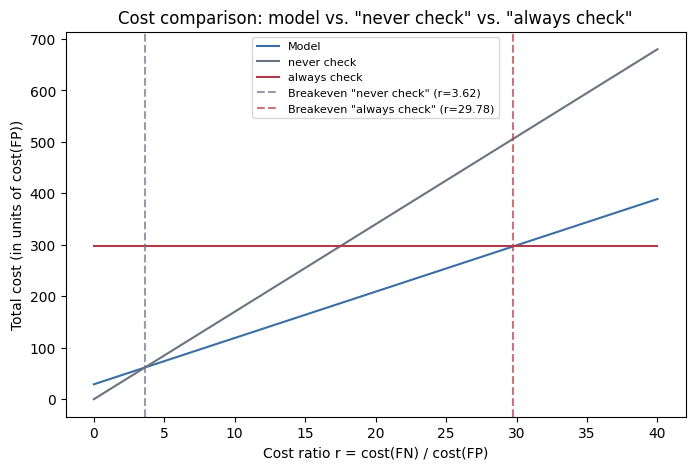

Sensitivity – with threshold 0.525: TN=271, FP=26, FN=11, TP=6 → breakeven r = 4.33 and r = 24.64, respectively


In [37]:
# Cost comparison: total cost of the model, "never check" and "always check" as a function
# of the cost ratio r = cost(FN) / cost(FP) (cost(FP) normalised to 1). Based on the
# confusion matrix of the reference model.

tn, fp, fn, tp = cm_log_reg.ravel()
print(f"Confusion matrix (reference model): TN={tn}, FP={fp}, FN={fn}, TP={tp}")

r_values = np.linspace(0, 40, 401)
cost_model = fp + fn * r_values
cost_never = (fn + tp) * r_values
cost_always = np.full_like(r_values, tn + fp, dtype=float)

r_break_never = fp / tp
r_break_always = tn / fn
print(f"Breakeven model vs. 'never check': r = {r_break_never:.2f}")
print(f"Breakeven model vs. 'always check': r = {r_break_always:.2f}")

plt.figure(figsize=(8, 5))
plt.plot(r_values, cost_model, label='Model', color='#3A6EA5')
plt.plot(r_values, cost_never, label='never check', color='#6B7280')
plt.plot(r_values, cost_always, label='always check', color='#B23A48')
plt.axvline(r_break_never, color='#6B7280', linestyle='--', alpha=0.7, label=f'Breakeven "never check" (r={r_break_never:.2f})')
plt.axvline(r_break_always, color='#B23A48', linestyle='--', alpha=0.7, label=f'Breakeven "always check" (r={r_break_always:.2f})')
plt.xlabel('Cost ratio r = cost(FN) / cost(FP)')
plt.ylabel('Total cost (in units of cost(FP))')
plt.title('Cost comparison: model vs. "never check" vs. "always check"')
plt.legend(fontsize=8)
plt.show()

# Sensitivity: with the MCC-optimised threshold (see section "Adjusting the decision
# threshold") TN/FP/FN/TP and hence the breakeven points shift, but the basic finding
# (the model lies between the two extreme strategies) remains.
tn_thr, fp_thr, fn_thr, tp_thr = confusion_matrix(y_test, y_pred_final_threshold).ravel()
r_break_never_thr = fp_thr / tp_thr
r_break_always_thr = tn_thr / fn_thr
print(f"Sensitivity – with threshold {best_threshold:.3f}: TN={tn_thr}, FP={fp_thr}, FN={fn_thr}, TP={tp_thr} "
      f"→ breakeven r = {r_break_never_thr:.2f} and r = {r_break_always_thr:.2f}, respectively")

### Diagnostic: deriving thresholds on training data vs. the full dataset

Checks whether the 30 % missing-value filter and the variability filter remove the same features when they are determined exclusively on the training data (as in the pipeline) instead of on the full dataset (as in the EDA, where thresholds were set without using the label). The overlap quantifies how strongly the thresholds set on the full dataset depend on the choice of data basis.

In [38]:
# Diagnostic: do the missing-value and low-variance filters remove the same features when
# they are determined on X_train only instead of the full dataset (sensors)?

# Missing-value filter: full dataset vs. training data only
missing_filter_full = MissingThresholdSelector(missing_threshold=0.3).fit(sensors)
removed_missing_full = set(sensors.columns) - set(missing_filter_full.kept_columns_)
removed_missing_train = set(X_train.columns) - set(missing_filter.kept_columns_)
print(f"Missing-value filter – removed features: full dataset {len(removed_missing_full)}, training only {len(removed_missing_train)}")
print(f"Overlap: {len(removed_missing_full & removed_missing_train)} of {len(removed_missing_full | removed_missing_train)} (union)")

# Low-variance filter: full dataset vs. training data only, each after its own
# missing-value filter and the same imputation (median)
sensors_full_imp = pd.DataFrame(
    SimpleImputer(strategy='median').fit_transform(missing_filter_full.transform(sensors)),
    columns=missing_filter_full.kept_columns_, index=sensors.index
)
variance_filter_full = LowVarianceFeatureSelector(cv_threshold=0.01).fit(sensors_full_imp)
removed_var_full = set(sensors_full_imp.columns) - set(variance_filter_full.kept_columns_)
removed_var_train = set(X_train_imp.columns) - set(selector.kept_columns_)
print(f"Low-variance filter – removed features: full dataset {len(removed_var_full)}, training only {len(removed_var_train)}")
print(f"Overlap: {len(removed_var_full & removed_var_train)} of {len(removed_var_full | removed_var_train)} (union)")

Missing-value filter – removed features: full dataset 32, training only 32
Overlap: 32 of 32 (union)
Low-variance filter – removed features: full dataset 129, training only 137
Overlap: 128 of 138 (union)


## Dashboard prototype

Interactive visualisation of the results within the notebook, in three areas: model overview with key performance metrics, relevant sensor features, and a single-case prediction for runs from the test set that can be selected via a dropdown.

In [39]:
# Dashboard based on the reference model (balanced logistic regression, default
# threshold 0.5). Interactive version: confusion matrix, model comparison and relevant
# features stay the same across all runs (global results); only the single-case panel
# is redrawn live via the dropdown.

plt.style.use('seaborn-v0_8-whitegrid')

PALETTE = {'failure': '#B23A48', 'passed': '#3A6EA5', 'neutral': '#6B7280'}

# Precomputations that are the same for every single case (not recomputed on every
# dropdown change)
coef_series = pd.Series(log_reg.coef_[0], index=X_train_scaled.columns)
important_feats = coef_series.abs().sort_values(ascending=False).head(min(8, len(coef_series))).index
pred_log_reg = log_reg.predict(X_test_scaled)
# The features actually passed into the model by the CorrelationFeatureSelector
# (not the general EDA ranking from further above)
relevant_features = corr_selector.correlations_[corr_selector.kept_columns_].sort_values(ascending=False)

def show_dashboard(row_index):
    fig = plt.figure(figsize=(15, 10))
    fig.suptitle('Prototype: fault detection in semiconductor manufacturing', fontsize=15, fontweight='bold')
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1], hspace=0.45, wspace=0.3)

    # First panel: confusion matrix with readable labels
    ax_cm = fig.add_subplot(gs[0, 0])
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, pred_log_reg),
        display_labels=['passed', 'failure']
    ).plot(ax=ax_cm, colorbar=False, cmap='Blues')
    ax_cm.set_xlabel('Predicted')
    ax_cm.set_ylabel('Actual')
    ax_cm.set_title('Confusion matrix – reference model', fontsize=11)
    ax_cm.grid(False)

    # Second panel: model comparison, horizontal instead of vertical
    ax_comp = fig.add_subplot(gs[0, 1])
    comparison.set_index('Model')[['F1 (failure)', 'MCC', 'ROC-AUC']].plot(
        kind='barh', ax=ax_comp, color=['#B23A48', '#3A6EA5', '#6B7280']
    )
    ax_comp.set_title('Model comparison: key performance metrics', fontsize=11)
    ax_comp.axvline(0, color='black', linewidth=0.8)
    ax_comp.set_xlabel('')
    # Legend placed below the bars instead of inside the plot, since it can never overlap
    # the bars there regardless of the data values.
    ax_comp.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)

    # Third panel: relevant sensor features
    ax_features = fig.add_subplot(gs[1, 0])
    relevant_features.plot(kind='barh', ax=ax_features, color=PALETTE['neutral'])
    ax_features.invert_yaxis()
    ax_features.set_xlabel('|Correlation with the failure label|')
    ax_features.set_title(f'Relevant sensor features (n={len(relevant_features)})', fontsize=11)

    # Fourth panel: single case, compact title in a text box instead of an axis title
    case = X_test_scaled.loc[row_index]
    actual = y_test.loc[row_index]
    prediction = log_reg.predict(X_test_scaled.loc[[row_index]])[0]
    proba = log_reg.predict_proba(X_test_scaled.loc[[row_index]])[0, 1]
    contributions = coef_series[important_feats] * case[important_feats]

    ax_case = fig.add_subplot(gs[1, 1])
    colors_case = [PALETTE['failure'] if v > 0 else PALETTE['passed'] for v in contributions.values]
    ax_case.barh(contributions.index.astype(str), contributions.values, color=colors_case)
    ax_case.invert_yaxis()
    ax_case.set_xlabel('Contribution to the prediction')
    ax_case.set_title(f'Single case {row_index} — P(failure) = {proba:.2f}', fontsize=11)

    status = 'correctly classified' if prediction == actual else 'misclassified'
    info_text = (
        f"Actual: {'failure' if actual == 1 else 'passed'}   |   "
        f"Predicted: {'failure' if prediction == 1 else 'passed'}   |   {status}"
    )
    fig.text(0.5, 0.02, info_text, ha='center', fontsize=10,
              bbox=dict(boxstyle='round', facecolor='#f0f0f0', edgecolor='#cccccc'))

    plt.tight_layout(rect=[0, 0.05, 1, 0.96])
    plt.show()


widgets.interact(
    show_dashboard,
    row_index=widgets.Dropdown(options=list(X_test_scaled.index), description='Run:')
);

interactive(children=(Dropdown(description='Run:', options=(1253, 1254, 1255, 1256, 1257, 1258, 1259, 1260, 12…

/var/folders/qh/dxrh_69x7n7d295dzkxm6s340000gn/T/ipykernel_1861/2493616880.py:76: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.05, 1, 0.96])


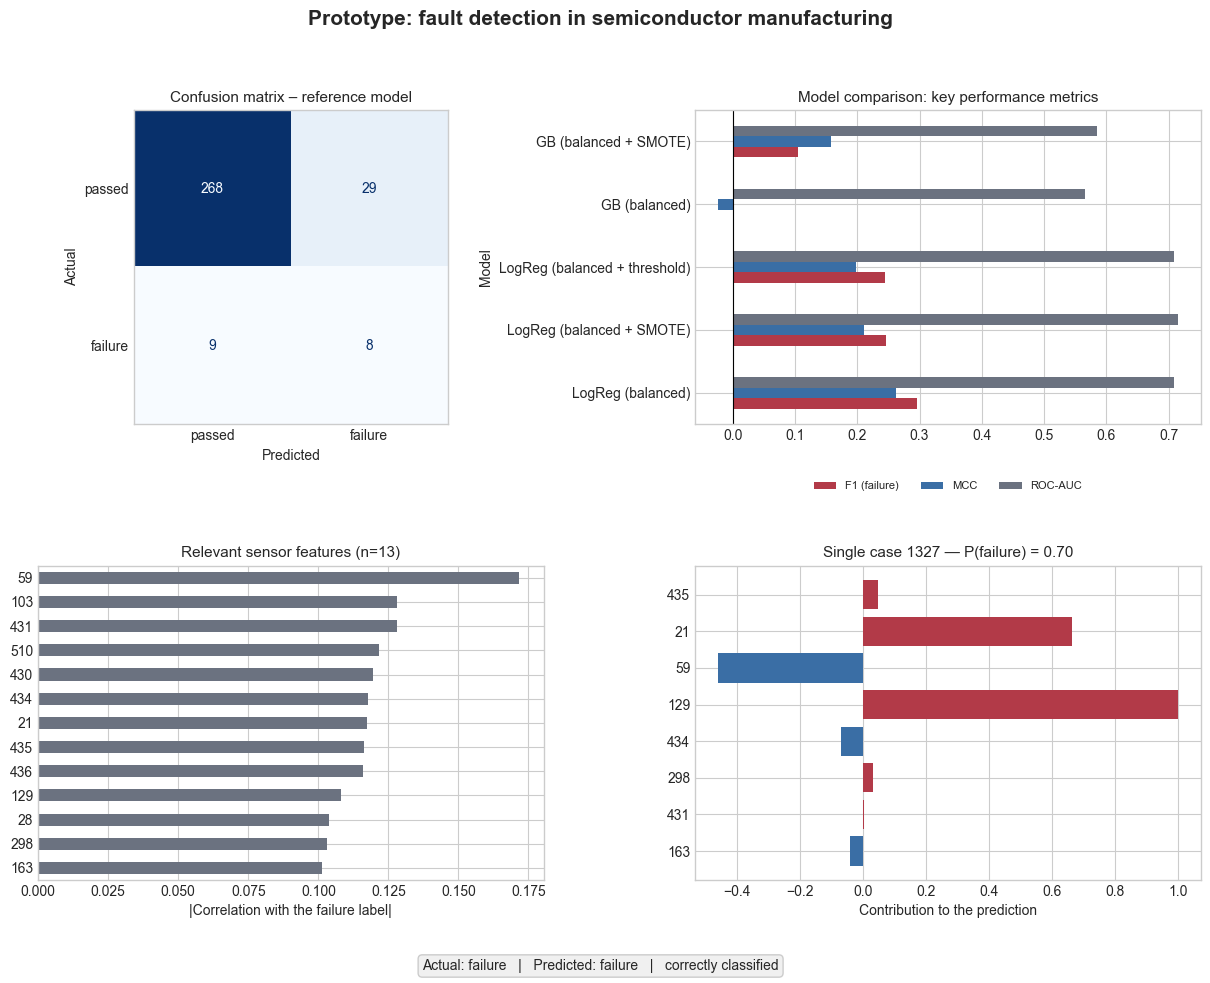

In [40]:
show_dashboard(1327)  # Example call for run 1327 so that the dashboard is visible immediately, even without interaction.